# Backpropagation for Feedforward Networks

**Course:** Artificial Neural Networks (20.IDI23) · **Mentor:** Prof. Branimir Todorović · **Author:** Elvir Muslić

The code half of the seminar paper. PyTorch's layers, automatic differentiation and gradient descent are the method, and the step by hand of Section 3.4 is the check. The notebook computes every number, table and figure of Sections 3.4, 4 and 5. Run it from this folder with `.venv/bin/jupyter nbconvert --to notebook --execute --inplace backprop_project.ipynb`.

## Part 0. Setup
The imports; double precision for every tensor, so that the gradient comparisons of Section 5.1 are meaningful; and the plot style, with 8 pt text and figures as wide as the paper's text. The last line prints the versions.

In [1]:
import logging
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch
from sklearn.datasets import make_moons
from torch import nn

%config InlineBackend.figure_format = "retina"

START = time.perf_counter()
torch.set_default_dtype(torch.float64)                          # double precision
Path("figures").mkdir(exist_ok=True)
# fontTools would warn about the old timestamps of the Computer Modern fonts that the PDFs embed
logging.getLogger("fontTools").setLevel(logging.ERROR)
TEXTWIDTH = 360 / 72.27                                         # the paper's text width in inches
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "mathtext.fontset": "cm", "lines.linewidth": 1.0,
    "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.6, "pdf.fonttype": 42,
    "figure.constrained_layout.use": True})

print(f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
      f"scikit-learn {sklearn.__version__}, Matplotlib {matplotlib.__version__}, "
      f"{platform.system()} {platform.machine()}")

Python 3.14.7, PyTorch 2.14.1, scikit-learn 1.9.1, Matplotlib 3.11.2, Darwin arm64


## Part 1. The method in PyTorch (Sections 2, 3 and 4)
A network is an `nn.Sequential` of layers: `nn.Linear(n_in, n_out)` holds the weights $W$ and the biases $b$ of a layer and computes $a = Wh + b$, and `nn.Tanh()` and `nn.Sigmoid()` apply the activations. The data hold one example per row. `train` runs full-batch gradient descent, and each of its steps has four parts:
- `model(X)` is the forward pass (2.1), Algorithm 1, for all examples at once;
- `0.5 * ((model(X) - Y) ** 2).mean()` is the loss (2.2), since the networks have one output unit;
- `loss.backward()` computes the gradient by automatic differentiation, which carries out Algorithm 2; `optimizer.zero_grad()` first clears the previous gradients, to which `backward()` would add;
- `optimizer.step()` applies the update (4.1) to every weight and bias.

`accuracy` gives the share of examples whose output, thresholded at 0.5, equals the label.

In [2]:
def train(model, X, Y, eta, steps):
    """Full-batch gradient descent; returns the loss before every step and after the last one."""
    optimizer = torch.optim.SGD(model.parameters(), lr=eta)
    losses = []
    for _ in range(steps):
        loss = 0.5 * ((model(X) - Y) ** 2).mean()     # forward pass and loss (2.2)
        losses.append(loss.item())
        optimizer.zero_grad()
        loss.backward()                                # Algorithm 2, by autograd
        optimizer.step()                               # update (4.1)
    losses.append(0.5 * ((model(X) - Y) ** 2).mean().item())
    return losses


def accuracy(model, X, Y):
    """The share of examples whose output, thresholded at 0.5, equals the label."""
    return ((model(X) > 0.5) == (Y > 0.5)).double().mean().item()

## Part 2. One step by hand (Sections 3.4 and 4)
### The forward and the backward pass: Table 1
The small network of Section 3.4: one input $x = 1$, one hidden and one output unit, both logistic, the weights $W^{(1)} = W^{(2)} = 0.5$, no biases, and the target $y = 1$. The lines follow Table 1: the forward pass (2.1) and the loss (2.2) with $N = 1$; then the backward pass, from the output back to the first weight: the output delta (3.2), the gradient (3.4) of $W^{(2)}$, the delta one layer back (3.3), and the gradient of $W^{(1)}$. The slope of the logistic function comes from its output, $\sigma'(a) = h(1 - h)$.

In [3]:
# the small network: x = 1, target y = 1, W1 = W2 = 0.5, no biases
x, y, W1, W2 = torch.tensor(1.0), torch.tensor(1.0), torch.tensor(0.5), torch.tensor(0.5)
a1 = W1 * x                                   # forward pass (2.1)
h1 = torch.sigmoid(a1)
a2 = W2 * h1
y_hat = torch.sigmoid(a2)
E = 0.5 * (y_hat - y) ** 2                    # loss (2.2) with N = 1
delta2 = (y_hat - y) * y_hat * (1 - y_hat)    # output delta (3.2)
dE_dW2 = delta2 * h1                          # gradient (3.4)
delta1 = delta2 * W2 * h1 * (1 - h1)          # delta one layer back (3.3)
dE_dW1 = delta1 * x                           # gradient (3.4)
values = dict(a1=a1, h1=h1, a2=a2, y_hat=y_hat, E=E, delta2=delta2, dE_dW2=dE_dW2, delta1=delta1,
              dE_dW1=dE_dW1)
print("\n".join(f"{name:>7} = {value:12.9f}" for name, value in values.items()))

     a1 =  0.500000000
     h1 =  0.622459331
     a2 =  0.311229666
  y_hat =  0.577185380
      E =  0.089386101
 delta2 = -0.103184702
 dE_dW2 = -0.064228280
 delta1 = -0.012124394
 dE_dW1 = -0.012124394


### One gradient-descent step (Section 4)
`loss_at` is the loss of the small network as a function of its two weights. One update (4.1) with $\eta = 1$ moves both weights against their gradients in Table 1.

In [4]:
def loss_at(w1, w2):
    """The loss of the small network as a function of its two weights."""
    return 0.5 * (torch.sigmoid(w2 * torch.sigmoid(w1 * x)) - y) ** 2


W1_new, W2_new = W1 - 1.0 * dE_dW1, W2 - 1.0 * dE_dW2   # one update (4.1) with eta = 1
print(f"after one step: W1 = {W1_new:.6f}, W2 = {W2_new:.6f}, "
      f"y_hat = {torch.sigmoid(W2_new * torch.sigmoid(W1_new * x)):.6f}")
print(f"E falls from {E:.6f} to {loss_at(W1_new, W2_new):.6f}")

after one step: W1 = 0.512124, W2 = 0.564228, y_hat = 0.587300
E falls from 0.089386 to 0.085161


## Part 3. Experiments (Sections 5.1–5.3)
### The hand step against autograd and central differences (Section 5.1)
The hand gradient of Table 1 in two other ways. Automatic differentiation (autograd): PyTorch records the operations of the forward pass, and `backward()` applies the chain rule to them in reverse order. Central differences (4.2) with $\epsilon = 10^{-6}$: each weight is changed by $\pm\epsilon$, and the change of the loss is divided by $2\epsilon$; no derivation is needed, but each weight costs two forward passes.

In [5]:
hand = torch.stack([dE_dW1, dE_dW2])                  # the hand gradient of Table 1
w = torch.tensor([0.5, 0.5], requires_grad=True)      # the same two weights, recorded by autograd
loss_at(w[0], w[1]).backward()                        # backpropagation by automatic differentiation

eps = 1e-6                                            # central differences (4.2)
fd = torch.stack([loss_at(0.5 + eps, 0.5) - loss_at(0.5 - eps, 0.5),
                  loss_at(0.5, 0.5 + eps) - loss_at(0.5, 0.5 - eps)]) / (2 * eps)

lines = [f"{'':20s}{'dE/dW1':>16s}{'dE/dW2':>16s}"]
for name, grad in {"by hand": hand, "autograd": w.grad, "central differences": fd}.items():
    lines.append(f"{name:20s}" + "".join(f"{v:16.12f}" for v in grad.tolist()))
lines.append("autograd differs from the hand gradient by at most "
             f"{(w.grad - hand).abs().max():.1e}")
lines.append("central differences differ from the hand gradient by "
             f"{(fd - hand)[0].abs():.1e} for W1 and {(fd - hand)[1].abs():.1e} for W2")
print("\n".join(lines))

                              dE/dW1          dE/dW2
by hand              -0.012124393984 -0.064228280480
autograd             -0.012124393984 -0.064228280480
central differences  -0.012124393982 -0.064228280451
autograd differs from the hand gradient by at most 1.4e-17
central differences differ from the hand gradient by 2.2e-12 for W1 and 2.9e-11 for W2


### XOR (Section 5.2)
The four inputs and their targets. A 2-4-1 network with $\tanh$ hidden units and a logistic output, PyTorch's default initial weights after `torch.manual_seed(0)`, $\eta = 1$ and 2000 steps.

In [6]:
X_xor = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])   # one example per row
Y_xor = torch.tensor([[0.0], [1.0], [1.0], [0.0]])
torch.manual_seed(0)
xor_net = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1), nn.Sigmoid())
xor_losses = train(xor_net, X_xor, Y_xor, eta=1.0, steps=2000)
print(f"XOR: 2-4-1 network, {sum(p.numel() for p in xor_net.parameters())} parameters, "
      f"eta = 1, {len(xor_losses) - 1} steps")
print(f"loss {xor_losses[0]:.4f} -> {xor_losses[-1]:.2e}, "
      f"outputs {[round(v, 2) for v in xor_net(X_xor).flatten().tolist()]}, "
      f"accuracy {accuracy(xor_net, X_xor, Y_xor):.2f}")

XOR: 2-4-1 network, 17 parameters, eta = 1, 2000 steps
loss 0.1261 -> 4.62e-04, outputs [0.03, 0.98, 0.97, 0.04], accuracy 1.00


### Two moons (Section 5.3)
Two interleaved half circles with Gaussian noise of standard deviation 0.1, from scikit-learn's `make_moons`: 200 training points and 200 test points, drawn with the seeds 0 and 1. A 2-16-1 network with $\tanh$ hidden units and a logistic output (seed 0) is trained on the training points with $\eta = 1$ for 5000 steps; the test points only measure the accuracy on new data.

In [7]:
def moons(n, seed):
    """n points of make_moons with noise 0.1, as tensors, with the labels as a column."""
    X, labels = make_moons(n_samples=n, noise=0.1, random_state=seed)
    return torch.tensor(X), torch.tensor(labels, dtype=torch.float64)[:, None]


X_train, Y_train = moons(200, seed=0)
X_test, Y_test = moons(200, seed=1)
torch.manual_seed(0)
moon_net = nn.Sequential(nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 1), nn.Sigmoid())
moon_losses = train(moon_net, X_train, Y_train, eta=1.0, steps=5000)
print(f"two moons: 2-16-1 network, {sum(p.numel() for p in moon_net.parameters())} parameters, "
      f"eta = 1, {len(moon_losses) - 1} steps, "
      f"{len(X_train)} training and {len(X_test)} test points")
print(f"loss {moon_losses[0]:.4f} -> {moon_losses[-1]:.4f}, "
      f"training accuracy {accuracy(moon_net, X_train, Y_train):.3f}, "
      f"test accuracy {accuracy(moon_net, X_test, Y_test):.3f}")

two moons: 2-16-1 network, 65 parameters, eta = 1, 5000 steps, 200 training and 200 test points
loss 0.1241 -> 0.0017, training accuracy 1.000, test accuracy 1.000


### Training loss $E$ after $k$ steps, Figures 1 and 2 (Sections 5.2 and 5.3)
The table gives the training loss $E$ of both networks at selected steps, and checks that it falls at every step. Figure 1 shows the loss at every step. Figure 2 shows the two moons and the decision boundary of the trained network, the curve on which its output equals 0.5, with the region of class 1 shaded darker: (a) the training points, (b) the test points; open circles are class 0 and filled triangles class 1.

training loss E after k steps
k                0     100     200     500    1000    2000    5000
XOR         0.1261  0.1236  0.1174  0.0181  0.0016  0.0005       -
two moons   0.1241  0.0444  0.0425  0.0414  0.0197  0.0058  0.0017
the loss falls at every step: XOR True, two moons True


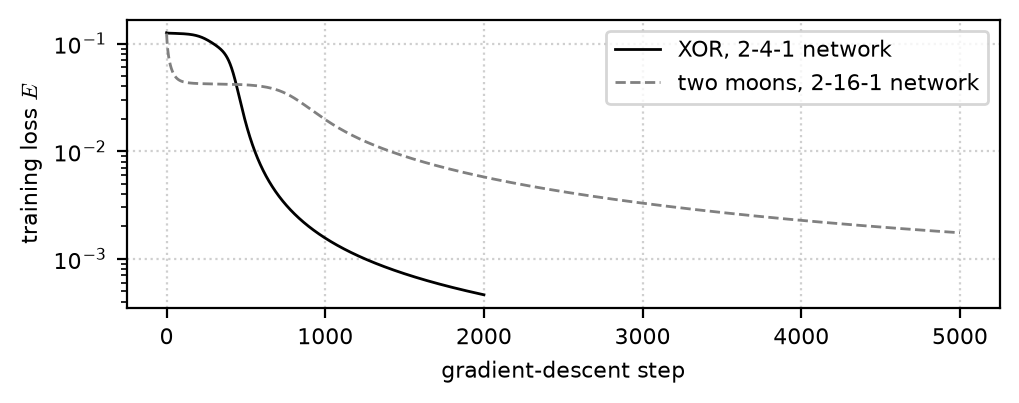

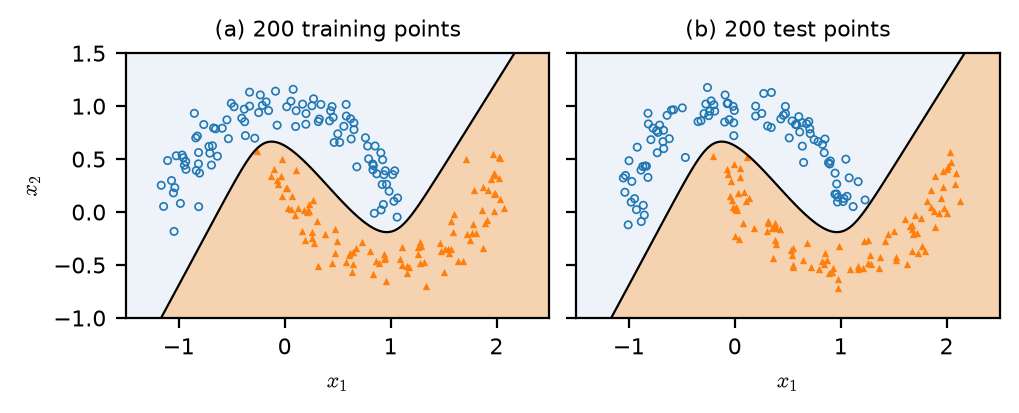

run time of the whole notebook: 2 s


In [8]:
STEPS = (0, 100, 200, 500, 1000, 2000, 5000)
RUNS = {"XOR": xor_losses, "two moons": moon_losses}
lines = ["training loss E after k steps", f"{'k':10s}" + "".join(f"{k:>8d}" for k in STEPS)]
for name, losses in RUNS.items():
    lines.append(f"{name:10s}" + "".join(f"{losses[k]:8.4f}" if k < len(losses) else f"{'-':>8s}"
                                         for k in STEPS))
falls = {name: all(b < a for a, b in zip(losses, losses[1:])) for name, losses in RUNS.items()}
lines.append("the loss falls at every step: " + ", ".join(f"{n} {v}" for n, v in falls.items()))
print("\n".join(lines))

fig, ax = plt.subplots(figsize=(TEXTWIDTH, 1.9))
ax.semilogy(xor_losses, "-", color="k", label="XOR, 2-4-1 network")
ax.semilogy(moon_losses, "--", color="0.5", label="two moons, 2-16-1 network")
ax.set(xlabel="gradient-descent step", ylabel="training loss $E$")
ax.legend(loc="upper right")
fig.savefig("figures/training_loss.pdf", metadata={"CreationDate": None})

# the output of the trained network on a grid, for the decision regions and the boundary
g1, g2 = torch.meshgrid(torch.linspace(-1.5, 2.5, 201), torch.linspace(-1.0, 1.5, 201),
                        indexing="xy")
with torch.no_grad():
    Z = moon_net(torch.stack([g1.flatten(), g2.flatten()], dim=1)).reshape(g1.shape)
fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.0), sharex=True, sharey=True)
for ax, X_, Y_, title in zip(axes, (X_train, X_test), (Y_train, Y_test),
                             ("(a) 200 training points", "(b) 200 test points")):
    # the region of class 1 darker than that of class 0, also in grayscale (218 against 242)
    ax.contourf(g1, g2, Z, levels=[0.0, 0.5, 1.0], colors=["#eef3f9", "#f6d3b0"])
    ax.contour(g1, g2, Z, levels=[0.5], colors="k", linewidths=0.8)
    # class 0: open circles, class 1: filled triangles, so that the classes differ in grayscale
    ax.scatter(*X_[Y_[:, 0] == 0].T, s=7, marker="o", facecolors="none", edgecolors="C0",
               linewidths=0.6)
    ax.scatter(*X_[Y_[:, 0] == 1].T, s=7, marker="^", color="C1", linewidths=0)
    ax.set(title=title, xlabel="$x_1$", aspect="equal")
    ax.grid(False)
axes[0].set_ylabel("$x_2$")
fig.savefig("figures/moons_boundary.pdf", metadata={"CreationDate": None})
plt.show()
print(f"run time of the whole notebook: {time.perf_counter() - START:.0f} s")